## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.


### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*

In [69]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy.stats as stats

%matplotlib inline

In [2]:
#1 Crosstab:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [7]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller']).sort_values(by=True, ascending=False)

crosstab_result

isBestSeller,False,True
category,,
Grocery,9008,556
Health & Personal Care,9017,552
Baby,14709,341
Sports & Outdoors,835935,330
Power & Hand Tools,8353,306
...,...,...
Blank Media Cases & Wallets,243,0
Boating Footwear,140,0
Boxes & Organisers,911,0


In [33]:
#Are there categories where being a best-seller is more prevalent?
def prop(x,y):
    proportion = x/y * 100
    return round(proportion,2)
crosstab_result['prop_best_sellers'] = crosstab_result.apply(lambda fila: prop(fila[True], fila[False]), axis=1)
crosstab_result.sort_values(by='prop_best_sellers', ascending=False)
top_5_sellers = crosstab_result.sort_values(by='prop_best_sellers', ascending=False).head(5)
top_5_sellers

isBestSeller,False,True,prop_best_sellers
category,,,
Grocery,9008,556,6.17
Smart Home Security & Lighting,98,6,6.12
Health & Personal Care,9017,552,6.12
Mobile Phone Accessories,248,11,4.44
Power & Hand Tools,8353,306,3.66


Podemos apreciar que los que mayor porporción de best sellers tienen son Grocery, Smart Home Security & Lighting y Health & Personal Care

2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

In [34]:
#H0 = the best-seller distribution is independent of the product category
#H1 = it depends on the product category
from scipy.stats import chi2_contingency
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

(np.float64(51286.99174092548), np.float64(0.0))

Como 0<0.05, descartamos la hipótesis nula y aceptamos la alternativa, osea que Sí depende de la categoría.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

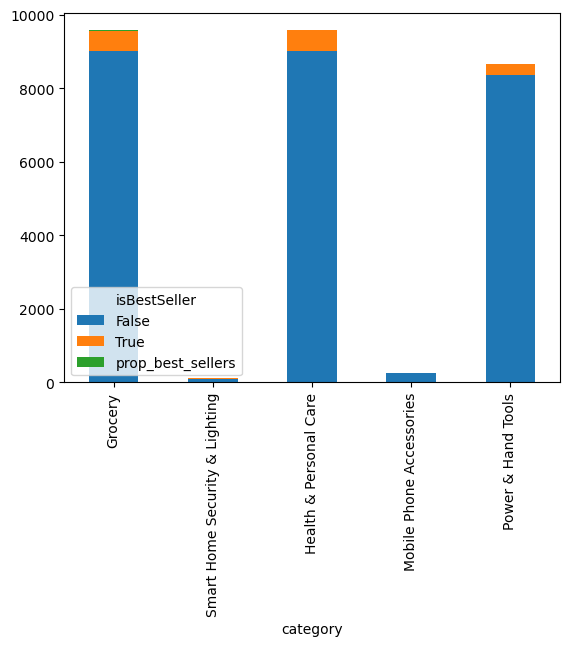

In [35]:
top_5_sellers.plot(kind="bar", stacked=True)
plt.show()

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

In [38]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Filtrar precios dentro del rango permitido
df_no_outliers = df[(df['price'] >= Q1 - 1.5 * IQR) & (df['price'] <= Q3 + 1.5 * IQR)]

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

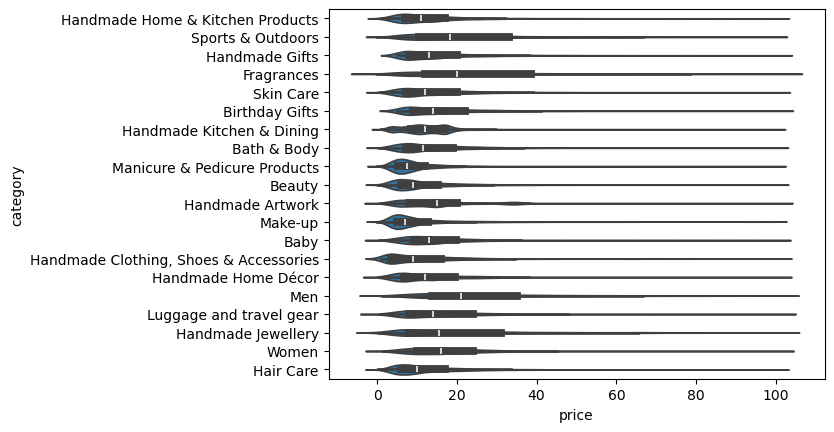

In [41]:
top_20 = df_no_outliers['category'].value_counts().nlargest(20).index
df_top = df_no_outliers[df_no_outliers['category'].isin(top_20)]
sns.violinplot(data=df_top, x='price', y='category')
plt.show()

In [ ]:
median_prices = df_no_outliers.groupby('category')['price'].median().sort_values(ascending=False)
median_prices
#Es Desktop PCs


category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

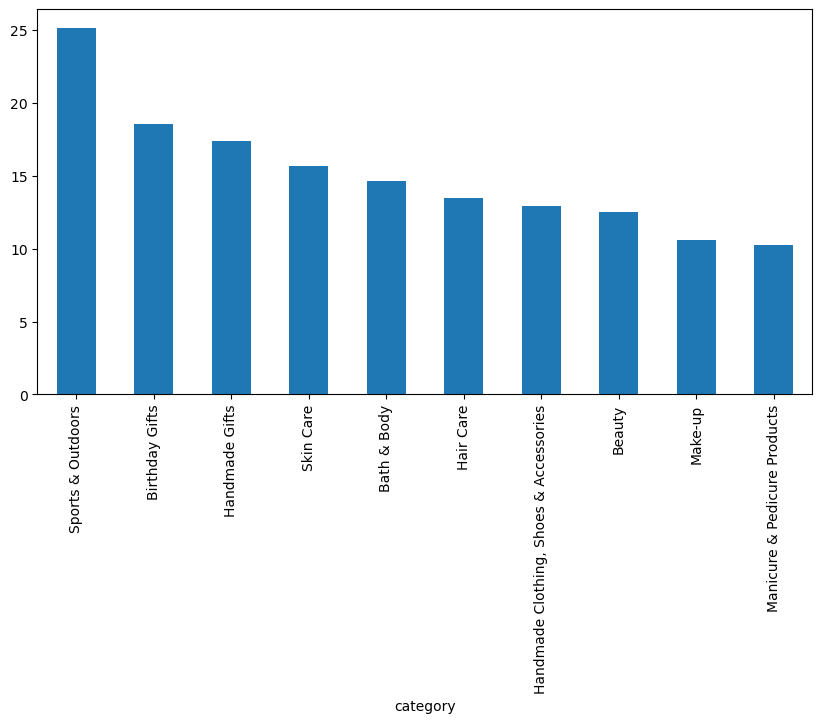

In [46]:
top_10 = df_no_outliers['category'].value_counts().nlargest(10).index
df_top = df_no_outliers[df_no_outliers['category'].isin(top_10)]
avg_price = df_top.groupby('category')['price'].mean().sort_values(ascending=False)
avg_price.plot(kind='bar', figsize=(10,5))
plt.show()

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

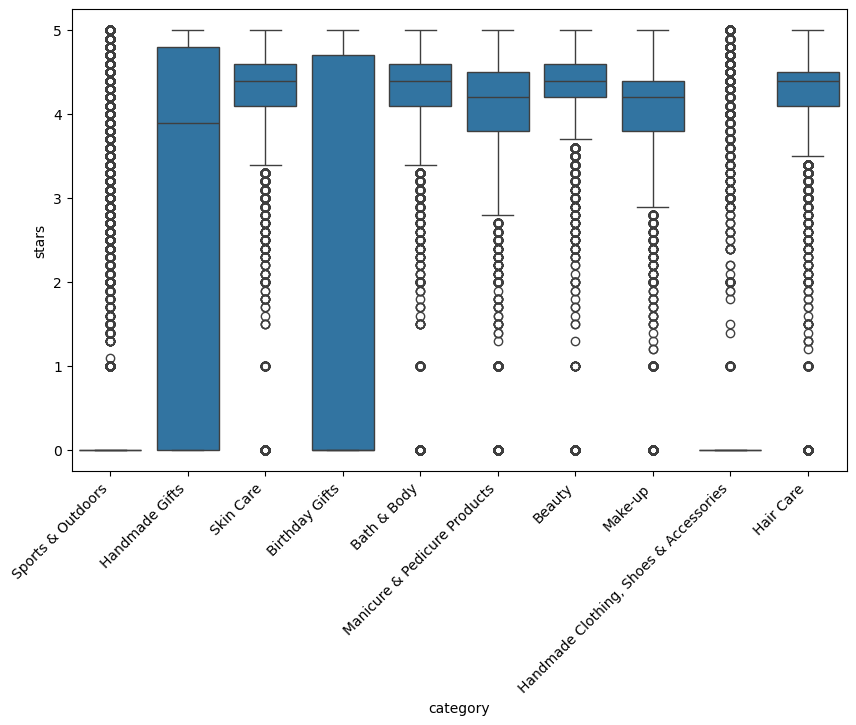

In [ ]:
top_10 = df_no_outliers['category'].value_counts().nlargest(10).index
df_top = df_no_outliers[df_no_outliers['category'].isin(top_10)]
plt.figure(figsize=(10,6))
sns.boxplot(data=df_top, x='category', y='stars')
plt.xticks(rotation=45, ha='right')
plt.show()

In [60]:
median_ratings = df_no_outliers.groupby('category')['stars'].median().sort_values(ascending=False)
median_ratings


category
Computer Memory                                 4.7
Beer, Wine & Spirits                            4.6
Building & Construction Toys                    4.6
Office Paper Products                           4.6
Kids' Play Figures                              4.6
                                               ... 
Synthesisers, Samplers & Digital Instruments    0.0
Tablets                                         0.0
Action Cameras                                  0.0
3D Printing & Scanning                          0.0
eBook Readers & Accessories                     0.0
Name: stars, Length: 296, dtype: float64

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?

In [62]:
correlation = df['price'].corr(df['stars'])
correlation

np.float64(-0.1249067326214861)

Es negativo, lo que indica una tendencia muy leve a que, cuando el precio aumenta, la valoración tiende a bajar un poco.

Sin embargo, es muy cercano  a 0, por lo que no existe una correlación significativa entre el precio y la valoración.

2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

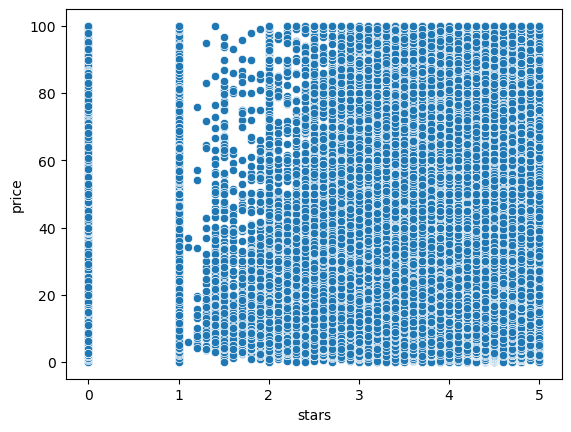

In [63]:

sns.scatterplot(data=df_no_outliers, x='stars', y='price')
plt.show()

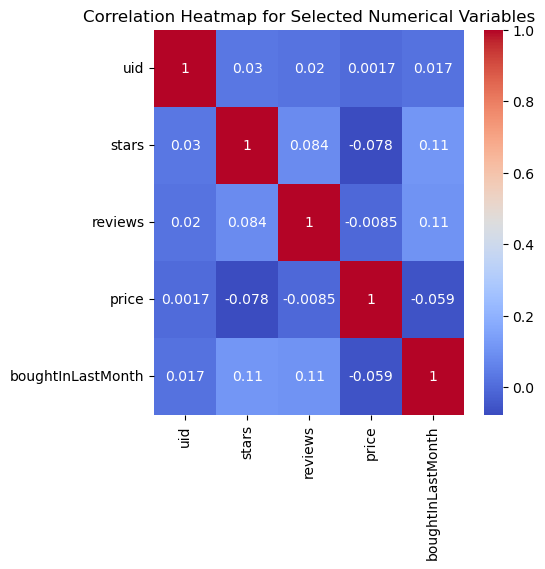

In [68]:
correlation_matrix = df_no_outliers.select_dtypes(include='number').corr()
plt.figure(figsize=(5, 5))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

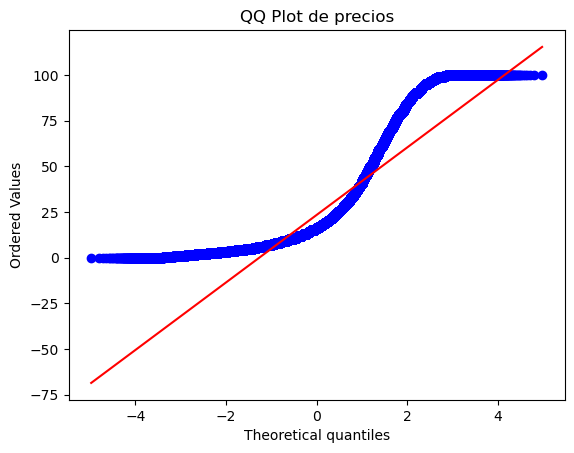

In [70]:
stats.probplot(df_no_outliers['price'], dist="norm", plot=plt)
plt.title('QQ Plot de precios')
plt.show()

### Insights
- Podemos apreciar que los que mayor porporción de best sellers tienen son Grocery, Smart Home Security & Lighting y Health &   Personal Care.
    Además podemos afirmar que ser un best seller está relacionado con la categoría a la que pertenece.
- La categoría con la mediana de precios más alta es Destktop PCs.
- La categoría con el precio medio más alto es Motherboards.
- La valoración mediana más alta es la de Computer Memory
- La QQ Plot nos muestra que el precio de los productos no sique una distribucion normal.